# SegFormer Semantic Segmentation — Single SEM / Wafer Defect Dataset
### Kaggle Notebook — one COCO dataset → 2x augmentation → SegFormer → loss curve, confusion matrix, Train/Validation/Test metrics

**Expected dataset structure:**
```text
<dataset-root>/
├── train/
│   ├── _annotations.coco.json
│   └── images...
├── valid/
│   ├── _annotations.coco.json
│   └── images...
└── test/
    ├── _annotations.coco.json
    └── images...
```

This corrected version is for **one dataset only**. It does not try to load Dataset 0–3 metrics and does not calculate a four-dataset weighted average.


## 1. Install & import

In [23]:
!pip install -q -U transformers albumentations pycocotools opencv-python-headless

In [24]:
import os, json, glob, random, copy, math
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import albumentations as A
from pycocotools.coco import COCO
from transformers import SegformerForSemanticSegmentation
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, accuracy_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## 2. Discover the single dataset folder
The notebook finds the folder containing `train/_annotations.coco.json` under `/kaggle/input/`.


In [25]:
hits = glob.glob("/kaggle/input/**/train/_annotations.coco.json", recursive=True)
if not hits:
    raise FileNotFoundError(
        "No train/_annotations.coco.json found under /kaggle/input. "
        "Attach your COCO dataset in Kaggle using Add Data."
    )

# Keep only unique dataset roots.
DATASET_ROOTS = sorted(set(os.path.dirname(os.path.dirname(h)) for h in hits))

if len(DATASET_ROOTS) > 1:
    print("WARNING: More than one COCO dataset folder was found:")
    for i, root in enumerate(DATASET_ROOTS):
        print(f"  [{i}] {root}")
    print("\nBecause this notebook is for ONE dataset, only the first folder will be used.")
    DATASET_ROOTS = [DATASET_ROOTS[0]]

DATASET_ROOT = DATASET_ROOTS[0]
print("Using dataset:", DATASET_ROOT)

for split in ("train", "valid", "test"):
    d = os.path.join(DATASET_ROOT, split)
    n = len([f for f in os.listdir(d) if f.lower().endswith((".jpg", ".jpeg", ".png"))]) if os.path.isdir(d) else 0
    print(f"{split}: {n} images")


Using dataset: /kaggle/input/datasets/hackathon07/sem-dataset-0/SEM wafer dataset-Folder- 0.coco
train: 67 images
valid: 19 images
test: 9 images


## 3. Build the category map
`0` is reserved for background; annotation categories are loaded from the single dataset.


In [26]:
def collect_categories(roots):
    canonical, order = {}, []
    for root in roots:
        json_path = os.path.join(root, "train", "_annotations.coco.json")
        if not os.path.exists(json_path):
            continue
        with open(json_path) as f:
            j = json.load(f)
        for c in sorted(j.get("categories", []), key=lambda c: c["id"]):
            name = c["name"]
            if name.lower() in ("nothing", "background"):
                continue
            key = name.lower()
            if key not in canonical:
                canonical[key] = name
                order.append(key)
    return [canonical[k] for k in order]

class_names = collect_categories(DATASET_ROOTS)
id2label = {0: "background"}
for i, name in enumerate(class_names, start=1):
    id2label[i] = name
label2id = {v: k for k, v in id2label.items()}
label2id_lower = {k.lower(): v for k, v in label2id.items()}

NUM_CLASSES = len(id2label)
print("Combined id2label:", id2label)
print("NUM_CLASSES:", NUM_CLASSES)

Combined id2label: {0: 'background', 1: 'SEM-wafer-dataset'}
NUM_CLASSES: 2


## 4. Build train / validation / test items


In [27]:
def build_split(roots, split):
    items = []
    for root in roots:
        split_dir = os.path.join(root, split)
        json_path = os.path.join(split_dir, "_annotations.coco.json")
        if not os.path.exists(json_path):
            continue
        coco = COCO(json_path)
        cats = coco.loadCats(coco.getCatIds())
        local_map = {c["id"]: label2id_lower[c["name"].lower()]
                     for c in cats if c["name"].lower() in label2id_lower}
        for img_id in coco.getImgIds():
            info = coco.loadImgs(img_id)[0]
            path = os.path.join(split_dir, info["file_name"])
            if os.path.exists(path):
                items.append({"coco": coco, "path": path, "info": info,
                              "cat_map": local_map, "root": root})
    return items

train_items = build_split(DATASET_ROOTS, "train")
valid_items = build_split(DATASET_ROOTS, "valid")
test_items  = build_split(DATASET_ROOTS, "test")

print(f"Combined totals: train={len(train_items)}  valid={len(valid_items)}  test={len(test_items)}")

summary_rows = []
for root in DATASET_ROOTS:
    summary_rows.append({
        "Dataset folder": root,
        "Train": sum(1 for it in train_items if it["root"] == root),
        "Valid": sum(1 for it in valid_items if it["root"] == root),
        "Test":  sum(1 for it in test_items  if it["root"] == root),
    })
pd.DataFrame(summary_rows)

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Combined totals: train=67  valid=19  test=9


,Dataset folder,Train,Valid,Test
0,/kaggle/input/datasets/hackathon07/sem-dataset...,67,19,9


## 5. COCO polygons → pixel masks

In [28]:
def _clean_segmentation(seg):
    """Drop degenerate polygons that crash pycocotools (empty, <3 points, odd coord count)."""
    if isinstance(seg, list):
        valid = [p for p in seg if isinstance(p, list) and len(p) >= 6 and len(p) % 2 == 0]
        return valid if valid else None
    return seg  # RLE dict form - leave as-is

def build_mask(item):
    """Rasterize all annotations for one item into a single-channel class-id mask.
    Malformed annotations (bad polygons) are skipped with a warning instead of crashing."""
    coco, info, cat_map = item["coco"], item["info"], item["cat_map"]
    h, w = info["height"], info["width"]
    mask = np.zeros((h, w), dtype=np.uint8)  # 0 = background
    ann_ids = coco.getAnnIds(imgIds=info["id"])
    anns = coco.loadAnns(ann_ids)
    for ann in anns:
        if ann["category_id"] not in cat_map:
            continue
        seg = ann.get("segmentation")
        if not seg:
            continue
        seg_clean = _clean_segmentation(seg)
        if seg_clean is None:
            print(f"Skipping empty/degenerate polygon: ann id={ann.get('id')} img={info.get('file_name')}")
            continue
        try:
            ann_for_mask = ann if seg_clean is seg else {**ann, "segmentation": seg_clean}
            m = coco.annToMask(ann_for_mask)
        except Exception as e:
            print(f"Skipping unrasterizable annotation id={ann.get('id')} img={info.get('file_name')}: {e}")
            continue
        mask[m == 1] = cat_map[ann["category_id"]]
    return mask

## 6. Visualize a sample image + mask

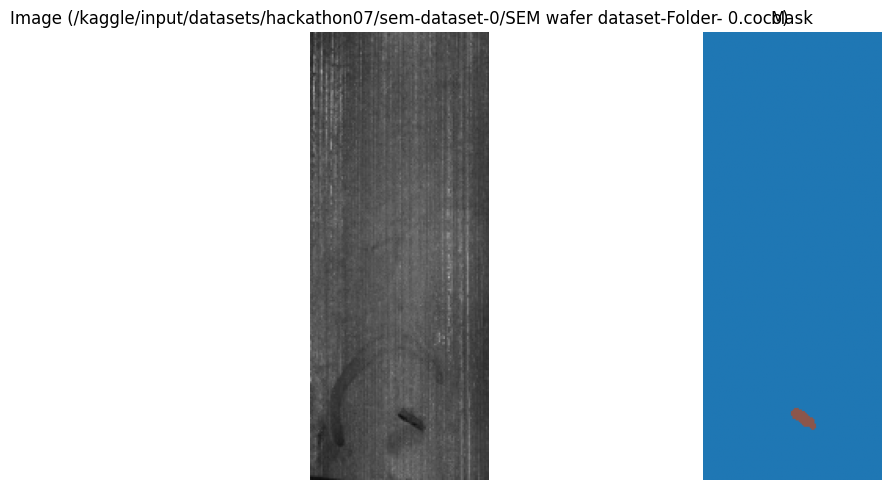

In [29]:
def show_sample(items, idx=0):
    item = items[idx]
    img = cv2.cvtColor(cv2.imread(item["path"]), cv2.COLOR_BGR2RGB)
    mask = build_mask(item)
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(img); ax[0].set_title(f"Image ({item['root']})"); ax[0].axis("off")
    ax[1].imshow(mask, cmap="tab20", vmin=0, vmax=NUM_CLASSES); ax[1].set_title("Mask"); ax[1].axis("off")
    plt.tight_layout(); plt.show()

show_sample(train_items, 0)

## 7. Augmentation pipeline (SEM-tuned) — doubles the training set
SEM/wafer images carry no real color information and are texture-heavy, so the pipeline favors geometric transforms
plus sensor-realistic noise/blur over color jitter.

`base_transform` = resize + normalize only (no randomness) — used for the "original" copy, and for valid/test.
`aug_transform` = the same, plus flips/rotation/affine/noise/blur/brightness/grid-distortion — used for the augmented copy.

In [30]:
IMG_SIZE = 512
MEAN = (0.485, 0.456, 0.406)
STD  = (0.229, 0.224, 0.225)

base_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=MEAN, std=STD),
])

aug_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    # Affine replaces the deprecated ShiftScaleRotate in newer Albumentations
    A.Affine(translate_percent=0.05, scale=(0.9, 1.1), rotate=(-15, 15),
              border_mode=cv2.BORDER_REFLECT, p=0.5),
    A.OneOf([
        A.GaussNoise(std_range=(0.02, 0.1)),   # newer API: fraction of max pixel value, replaces var_limit
        A.MultiplicativeNoise(multiplier=(0.9, 1.1)),
    ], p=0.4),
    A.OneOf([
        A.GaussianBlur(blur_limit=(3, 5)),
        A.MotionBlur(blur_limit=3),
    ], p=0.3),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
    A.GridDistortion(num_steps=5, distort_limit=0.1, p=0.2),
    A.Normalize(mean=MEAN, std=STD),
])

## 8. PyTorch Dataset

In [31]:
class SEMSegDataset(Dataset):
    def __init__(self, items, transform):
        self.items, self.transform = items, transform

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        item = self.items[idx]
        img = cv2.cvtColor(cv2.imread(item["path"]), cv2.COLOR_BGR2RGB)
        mask = build_mask(item)
        out = self.transform(image=img, mask=mask)
        pixel_values = torch.tensor(out["image"]).permute(2, 0, 1).float()
        label = torch.tensor(out["mask"]).long()
        return {"pixel_values": pixel_values, "labels": label}

# "Augment the dataset twice": the training set = originals (resize+normalize only)
# CONCATENATED with an augmented copy (full random augmentation) -> 2x samples/epoch.
train_plain = SEMSegDataset(train_items, base_transform)
train_aug   = SEMSegDataset(train_items, aug_transform)
train_dataset = ConcatDataset([train_plain, train_aug])

valid_dataset = SEMSegDataset(valid_items, base_transform)
test_dataset  = SEMSegDataset(test_items,  base_transform)

print("Train samples (2x augmented):", len(train_dataset))
print("Valid samples:", len(valid_dataset))
print("Test samples:", len(test_dataset))

Train samples (2x augmented): 134
Valid samples: 19
Test samples: 9


## 9. DataLoaders

In [32]:
BATCH_SIZE = 4  # small dataset -> keep batch size modest

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=1,          shuffle=False, num_workers=2, pin_memory=True)

## 10. Class weights (handle imbalance) + model
Wafer defect masks are almost always background-dominant. Weighting the loss by inverse pixel frequency
usually helps recall/F1 on the minority (defect) class.

In [33]:
class_pixels = np.zeros(NUM_CLASSES, dtype=np.int64)
for item in train_items:
    m = build_mask(item)
    counts = np.bincount(m.flatten(), minlength=NUM_CLASSES)
    class_pixels += counts

freq = class_pixels / class_pixels.sum()
class_weights = 1.0 / np.log(1.02 + freq)          # log-smoothed inverse frequency
class_weights = class_weights / class_weights.mean()
class_weights_t = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
print("Class pixel freq:", dict(zip(id2label.values(), freq.round(4))))
print("Class weights   :", dict(zip(id2label.values(), class_weights.round(3))))

Class pixel freq: {'background': np.float64(0.9979), 'SEM-wafer-dataset': np.float64(0.0021)}
Class weights   : {'background': np.float64(0.06), 'SEM-wafer-dataset': np.float64(1.94)}


### About the warnings you'll see loading `nvidia/mit-b0`
Two things below are **expected, not errors**:
- *"You are sending unauthenticated requests to the HF Hub"* — just means downloads use the public rate limit; harmless for a one-time model download. Ignore it, or add an `HF_TOKEN` as a Kaggle Secret if you want faster/higher-limit downloads.
- *"num_labels=X incompatible with id2label map of length 1000"* + a LOAD REPORT with `classifier` as UNEXPECTED and `decode_head.*` as MISSING — `nvidia/mit-b0` is an ImageNet-pretrained **backbone only** checkpoint (1000-class classifier, no segmentation head). Loading it for segmentation correctly discards that ImageNet classifier and randomly initializes a fresh decode head sized to your `NUM_CLASSES` — the encoder weights that actually matter for transfer learning do carry over. `set_verbosity_error()` below just quiets the noisy report; the "Trainable params" line printed after is your real confirmation it loaded.

In [34]:
from transformers import logging as hf_logging
hf_logging.set_verbosity_error()  # suppress the informational (expected) load-report noise explained above

model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/mit-b0",
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
).to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights_t, ignore_index=255)
print(f"Model loaded. Trainable params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

Model loaded. Trainable params: 3,714,658


## 11. Training — AdamW optimizer, epochs sized to the merged dataset
Instead of a fixed epoch count, `EPOCHS` is derived from how many training samples you actually have (after 2x
augmentation): the target is a roughly constant total number of gradient updates (`TARGET_UPDATES`), so a smaller
merged dataset trains for more epochs and a larger one for fewer — clipped to a sane `[MIN_EPOCHS, MAX_EPOCHS]`
range, with early stopping (`PATIENCE`) as a safety net regardless of how many epochs are scheduled.

In [35]:
TARGET_UPDATES = 2000     # roughly how many gradient steps a MiT-B0 fine-tune on this data size wants
MIN_EPOCHS, MAX_EPOCHS = 25, 150
LR = 6e-5
WEIGHT_DECAY = 1e-4
PATIENCE = 8

steps_per_epoch = math.ceil(len(train_dataset) / BATCH_SIZE)
EPOCHS = int(np.clip(round(TARGET_UPDATES / steps_per_epoch), MIN_EPOCHS, MAX_EPOCHS))
print(f"Merged train set: {len(train_dataset)} samples (2x aug) | batch={BATCH_SIZE} | "
      f"steps/epoch={steps_per_epoch}")
print(f"-> EPOCHS set to {EPOCHS} (~{EPOCHS * steps_per_epoch} total gradient updates)")

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def forward_loss(model, pixel_values, labels):
    outputs = model(pixel_values=pixel_values)
    logits = outputs.logits  # (B, num_labels, H/4, W/4)
    logits_up = nn.functional.interpolate(logits, size=labels.shape[-2:], mode="bilinear", align_corners=False)
    loss = criterion(logits_up, labels)
    return loss, logits_up

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, n_batches = 0.0, 0
    with torch.set_grad_enabled(train):
        for batch in loader:
            pixel_values = batch["pixel_values"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)
            if train:
                optimizer.zero_grad()
            loss, _ = forward_loss(model, pixel_values, labels)
            if train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item()
            n_batches += 1
    return total_loss / max(n_batches, 1)

Merged train set: 134 samples (2x aug) | batch=4 | steps/epoch=34
-> EPOCHS set to 59 (~2006 total gradient updates)


In [36]:
history = {"train_loss": [], "val_loss": []}
best_val_loss = float("inf")
best_state = None
patience_ctr = 0

for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(train_loader, train=True)
    val_loss = run_epoch(valid_loader, train=False)
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    print(f"Epoch {epoch:02d}/{EPOCHS} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f}")

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        patience_ctr = 0
    else:
        patience_ctr += 1
        if patience_ctr >= PATIENCE:
            print(f"Early stopping at epoch {epoch} (no val improvement for {PATIENCE} epochs).")
            break

model.load_state_dict(best_state)
print(f"Loaded best model (val_loss={best_val_loss:.4f}).")

Epoch 01/59 | train_loss=0.5200 | val_loss=0.5195
Epoch 02/59 | train_loss=0.3314 | val_loss=0.3462
Epoch 03/59 | train_loss=0.2430 | val_loss=0.2333
Epoch 04/59 | train_loss=0.1980 | val_loss=0.1661
Epoch 05/59 | train_loss=0.1703 | val_loss=0.1691
Epoch 06/59 | train_loss=0.1402 | val_loss=0.1335
Epoch 07/59 | train_loss=0.1232 | val_loss=0.1075
Epoch 08/59 | train_loss=0.1051 | val_loss=0.0897
Epoch 09/59 | train_loss=0.0921 | val_loss=0.1245
Epoch 10/59 | train_loss=0.0786 | val_loss=0.0769
Epoch 11/59 | train_loss=0.0792 | val_loss=0.0720
Epoch 12/59 | train_loss=0.0823 | val_loss=0.0503
Epoch 13/59 | train_loss=0.0727 | val_loss=0.0771
Epoch 14/59 | train_loss=0.0678 | val_loss=0.0568
Epoch 15/59 | train_loss=0.0585 | val_loss=0.0537
Epoch 16/59 | train_loss=0.0517 | val_loss=0.0424
Epoch 17/59 | train_loss=0.0529 | val_loss=0.0661
Epoch 18/59 | train_loss=0.0476 | val_loss=0.0354
Epoch 19/59 | train_loss=0.0425 | val_loss=0.0438
Epoch 20/59 | train_loss=0.0390 | val_loss=0.0504


## 12. Loss graph

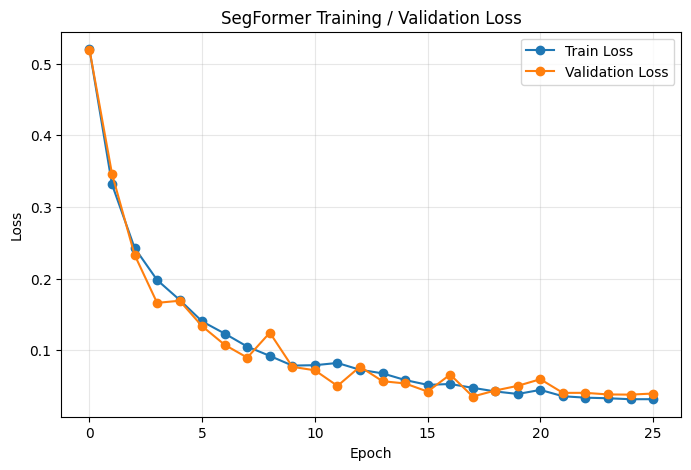

In [37]:
plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], label="Train Loss", marker="o")
plt.plot(history["val_loss"], label="Validation Loss", marker="o")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("SegFormer Training / Validation Loss")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("/kaggle/working/loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## 13. Evaluate on Train / Validation / Test
`predict_mask` runs the model; `evaluate_dataset` scores a whole split. **Train is evaluated with `train_plain`
(resize+normalize only, no random augmentation)** so the score reflects real performance, not augmented pixels.

In [38]:
@torch.no_grad()
def predict_mask(model, pixel_values, out_hw):
    outputs = model(pixel_values=pixel_values.to(DEVICE))
    logits_up = nn.functional.interpolate(outputs.logits, size=out_hw, mode="bilinear", align_corners=False)
    return logits_up.argmax(dim=1).cpu().numpy()

@torch.no_grad()
def evaluate_dataset(dataset, batch_size=4):
    """Runs inference over a full split and returns overall Precision/Recall/Accuracy/F1
    (weighted across classes - the fair read when background dominates pixel counts),
    plus the flattened y_true/y_pred for confusion-matrix use."""
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    model.eval()
    all_preds, all_labels = [], []
    for batch in loader:
        pixel_values = batch["pixel_values"]
        labels = batch["labels"].numpy()
        pred = predict_mask(model, pixel_values, labels.shape[-2:])
        all_preds.append(pred.reshape(-1))
        all_labels.append(labels.reshape(-1))
    y_pred = np.concatenate(all_preds)
    y_true = np.concatenate(all_labels)

    acc = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(NUM_CLASSES)), average="weighted", zero_division=0
    )
    metrics = {"Precision": precision, "Recall": recall, "Accuracy": acc, "F1 Score": f1}
    return metrics, y_true, y_pred

split_metrics = {}
split_metrics["Train"],      y_true_train, y_pred_train = evaluate_dataset(train_plain)
split_metrics["Validation"], y_true_valid, y_pred_valid = evaluate_dataset(valid_dataset)
split_metrics["Test"],       y_true_test,  y_pred_test  = evaluate_dataset(test_dataset)

split_preds = {
    "Train": (y_true_train, y_pred_train),
    "Validation": (y_true_valid, y_pred_valid),
    "Test": (y_true_test, y_pred_test),
}

for split, m in split_metrics.items():
    print(split, {k: round(v, 4) for k, v in m.items()})

Train {'Precision': 0.9985, 'Recall': 0.9965, 'Accuracy': 0.9965, 'F1 Score': 0.9972}
Validation {'Precision': 0.9985, 'Recall': 0.9966, 'Accuracy': 0.9966, 'F1 Score': 0.9973}
Test {'Precision': 0.999, 'Recall': 0.9967, 'Accuracy': 0.9967, 'F1 Score': 0.9976}


## 14. Comparison table — Precision / Recall / Accuracy / F1 Score

In [39]:
comparison_df = pd.DataFrame(split_metrics).T.reset_index().rename(columns={"index": "Dataset"})
comparison_df = comparison_df[["Dataset", "Precision", "Recall", "Accuracy", "F1 Score"]].round(4)

METRICS_CSV = "/kaggle/working/segformer_single_dataset_metrics_comparison.csv"
comparison_df.to_csv(METRICS_CSV, index=False)

print("Saved metrics:", METRICS_CSV)
comparison_df


Saved metrics: /kaggle/working/segformer_single_dataset_metrics_comparison.csv


,Dataset,Precision,Recall,Accuracy,F1 Score
0,Train,0.9985,0.9965,0.9965,0.9972
1,Validation,0.9985,0.9966,0.9966,0.9973
2,Test,0.9990,0.9967,0.9967,0.9976


## 15. Confusion Matrix (Test set)

In [40]:
# -----------------------------------------------------------------------------
# SINGLE-DATASET RESULT SUMMARY
# -----------------------------------------------------------------------------
# No Dataset 0-3 loop is needed here. The model was trained and evaluated on
# the one dataset attached to this notebook.

test_result = comparison_df[
    comparison_df["Dataset"].astype(str).str.strip().str.lower() == "test"
].copy()

if len(test_result) != 1:
    raise ValueError(f"Expected exactly one Test row, found {len(test_result)}.")

test_result = test_result.reset_index(drop=True)
print("Single-dataset Test metrics:")
display(test_result)

# Optional Excel export containing all Train / Validation / Test metrics.
METRICS_XLSX = "/kaggle/working/segformer_single_dataset_metrics_comparison.xlsx"
comparison_df.to_excel(METRICS_XLSX, index=False)
print("Saved Excel:", METRICS_XLSX)


Single-dataset Test metrics:


,Dataset,Precision,Recall,Accuracy,F1 Score
0,Test,0.999,0.9967,0.9967,0.9976


Saved Excel: /kaggle/working/segformer_single_dataset_metrics_comparison.xlsx


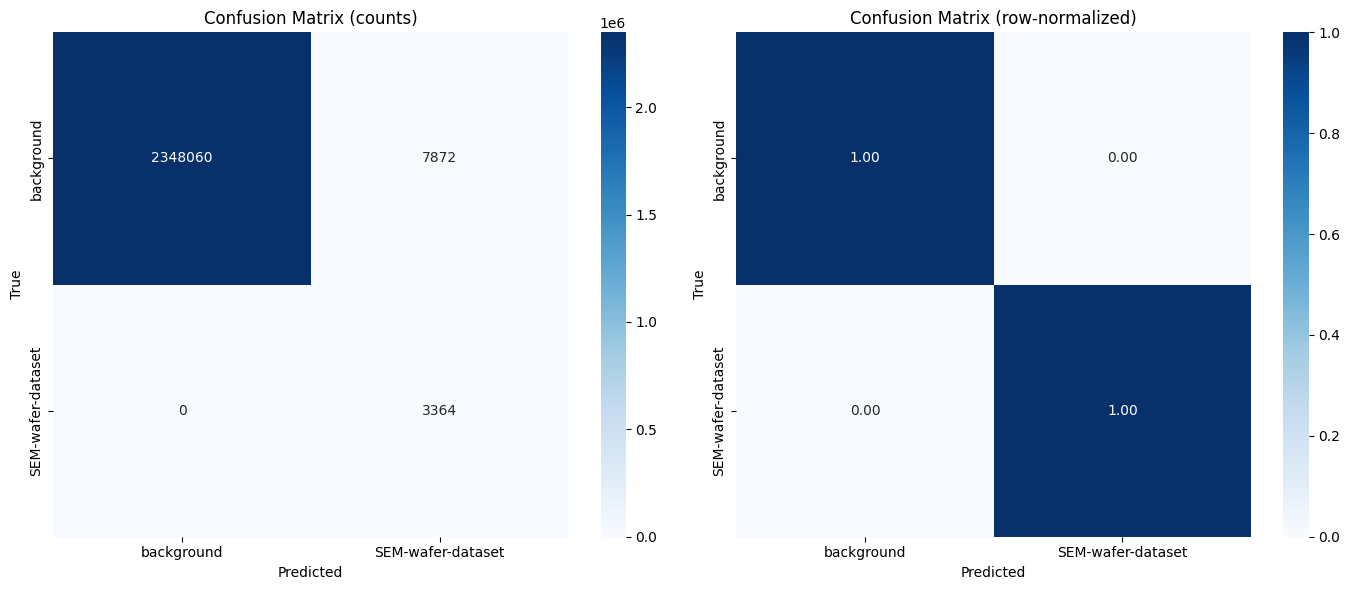

In [41]:
y_true, y_pred = split_preds["Test"]
labels_order = list(range(NUM_CLASSES))
cm = confusion_matrix(y_true, y_pred, labels=labels_order)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[id2label[i] for i in labels_order],
            yticklabels=[id2label[i] for i in labels_order], ax=ax[0])
ax[0].set_title("Confusion Matrix (counts)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=[id2label[i] for i in labels_order],
            yticklabels=[id2label[i] for i in labels_order], ax=ax[1])
ax[1].set_title("Confusion Matrix (row-normalized)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("True")

plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## 16. Target check — F1 ≥ 0.85

In [42]:
TARGET_F1 = 0.85
achieved = split_metrics["Test"]["F1 Score"]

print(f"Target F1: {TARGET_F1:.2f}  |  Achieved Test F1: {achieved:.4f}")
if achieved >= TARGET_F1:
    print("Target F1 reached.")
else:
    gap = TARGET_F1 - achieved
    print(f"{gap:.4f} short of target. Highest-impact things to try:")
    print(" 1. Check annotation quality and consistency.")
    print(" 2. Train for more updates or try a larger SegFormer backbone.")
    print(" 3. Strengthen augmentation.")
    print(" 4. Tune class weights for the rarer defect class.")
    print(" 5. Increase image size if very fine defects are being lost.")
    if split_metrics["Train"]["F1 Score"] - achieved > 0.15:
        print("Train F1 is much higher than Test F1, suggesting overfitting.")


Target F1: 0.85  |  Achieved Test F1: 0.9976
Target F1 reached.


## 17. Qualitative check — 10 random test predictions
Run the notebook from the top so the trained model and dataset objects exist in the current kernel session.


Showing 9 random test image(s) - indices [1, 0, 5, 2, 8, 4, 7, 6, 3] (merged test split has 9 image(s) total).


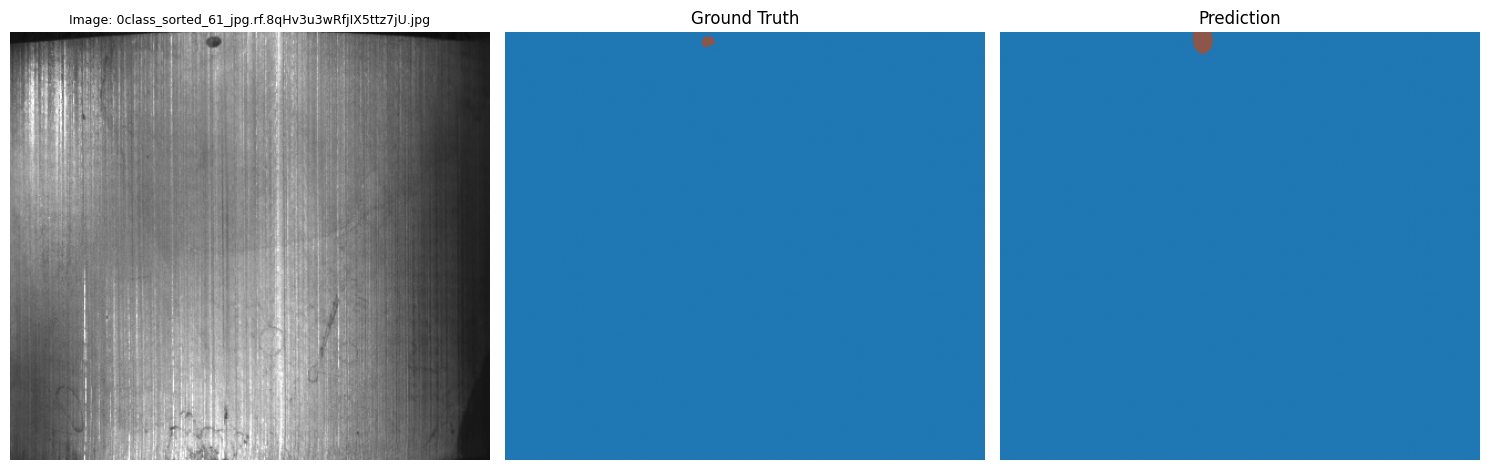

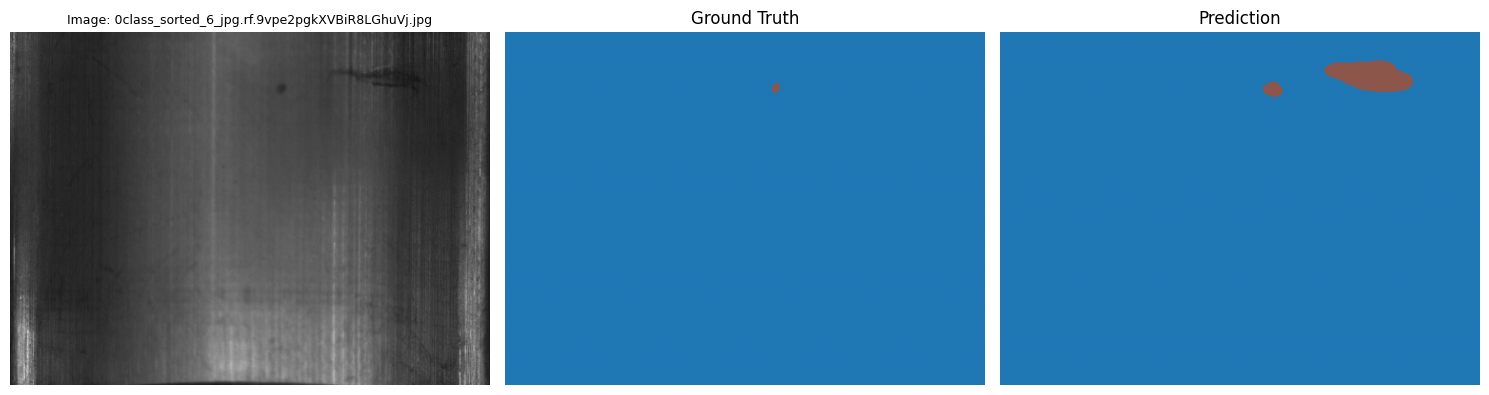

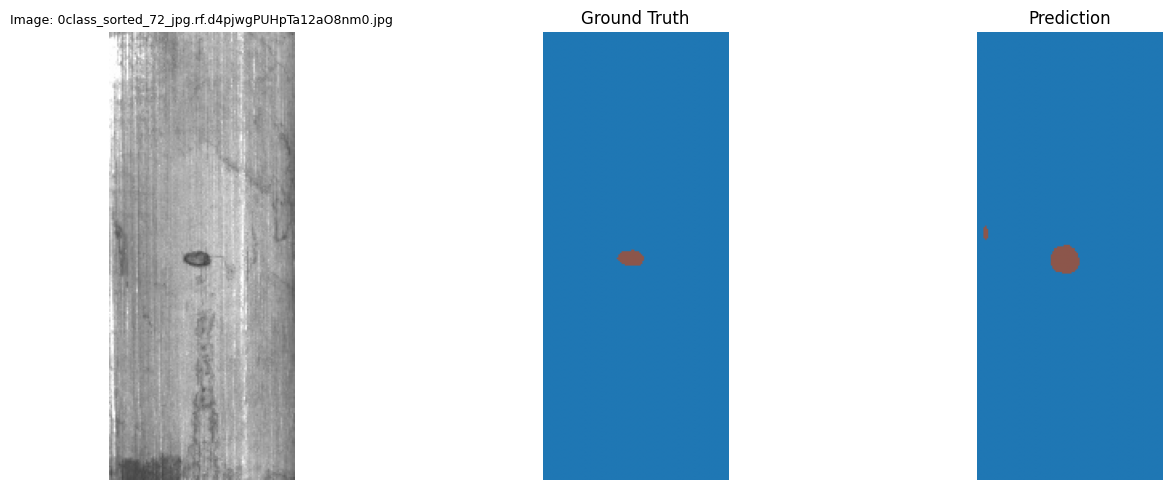

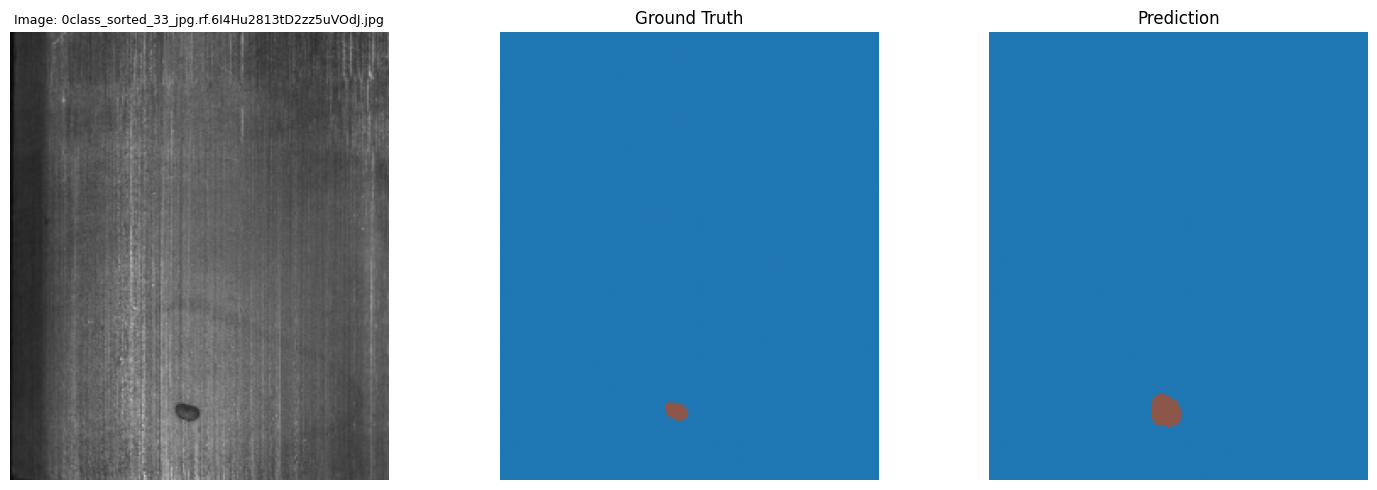

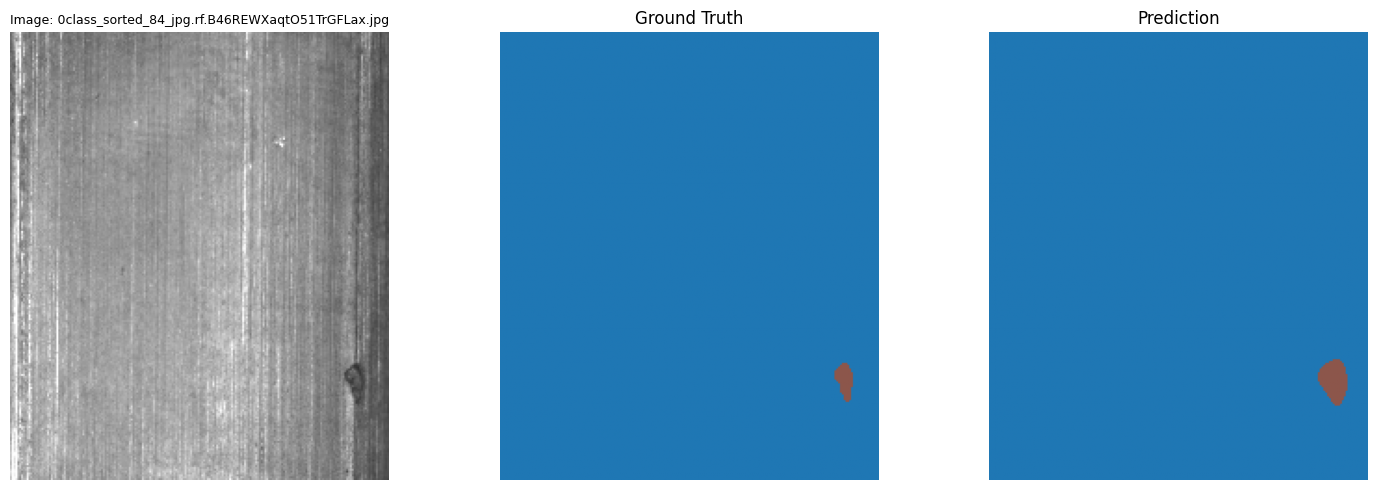

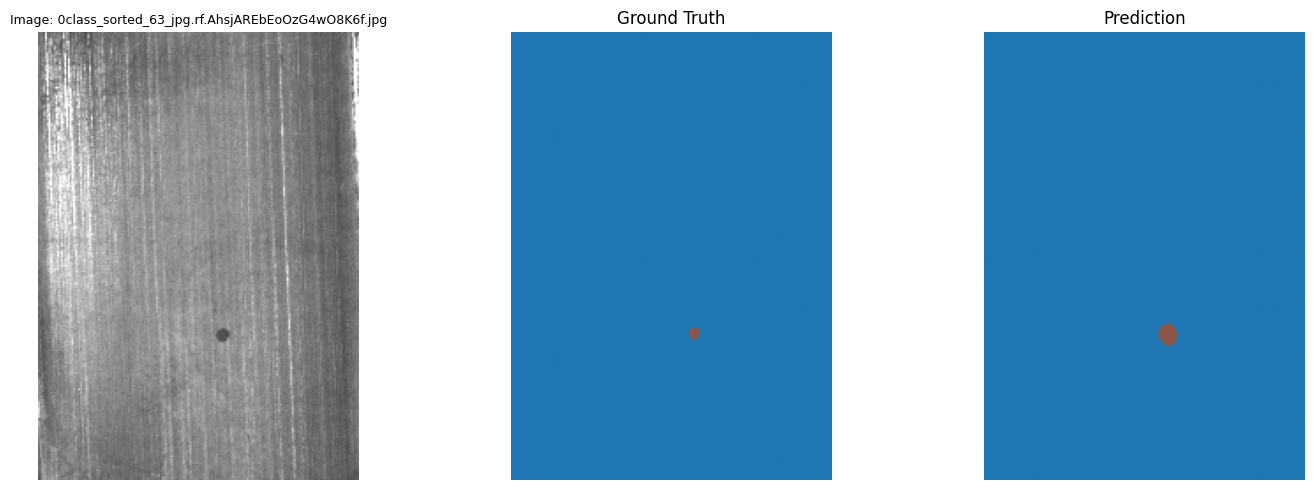

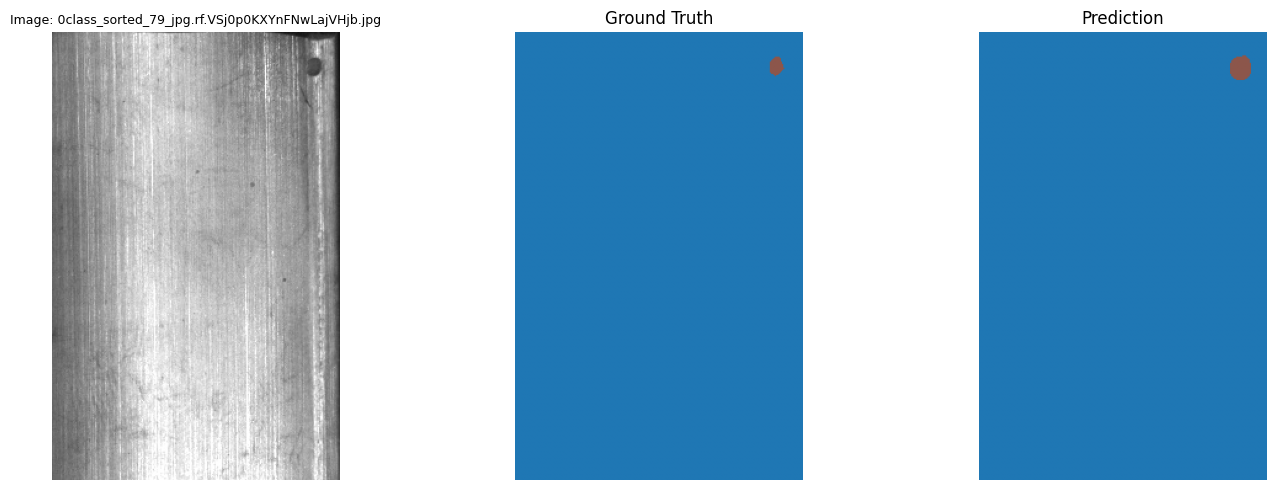

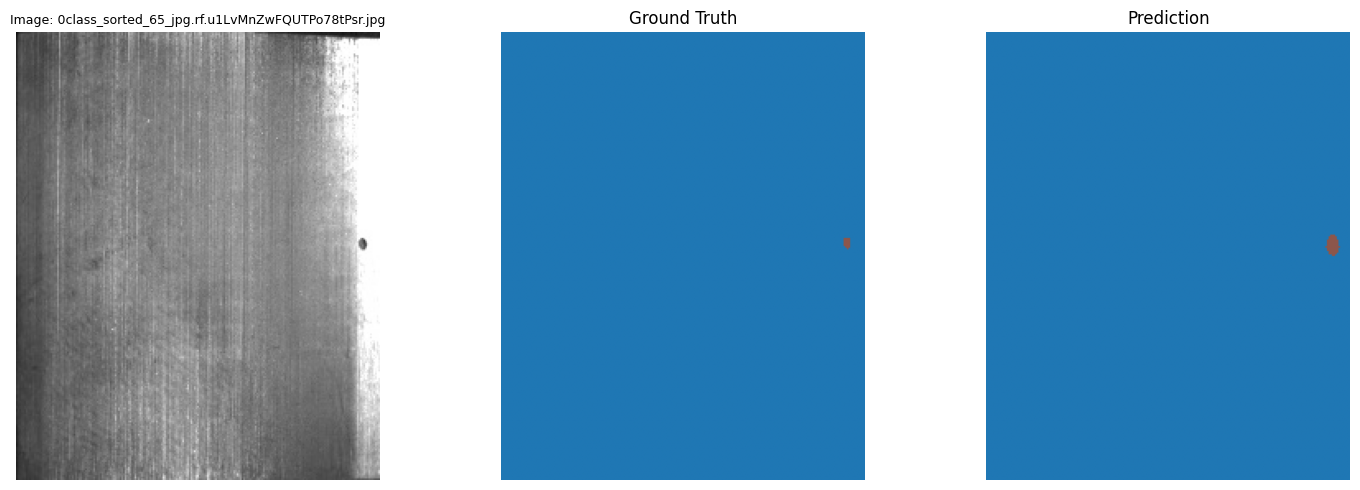

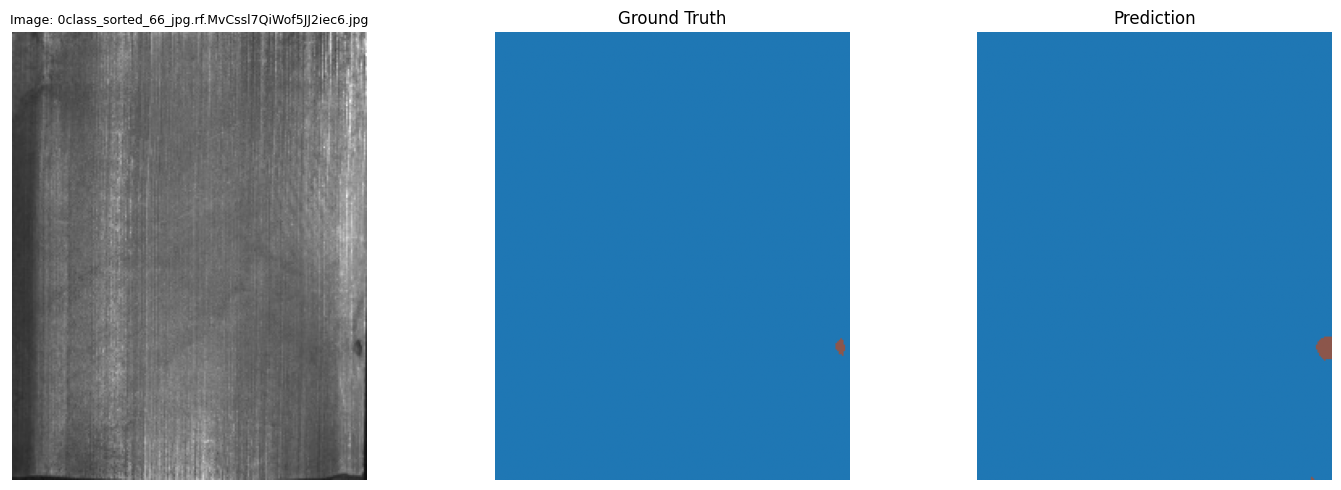

In [43]:
import random

required_vars = ["DATASET_ROOTS", "label2id_lower", "NUM_CLASSES", "base_transform", "model", "predict_mask"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise RuntimeError(
        f"Missing from this session: {missing}. Use Run All from the top of the notebook - "
        "this cell needs the merged dataset objects (Sections 2-4) AND the trained model "
        "(Sections 10-11) to already exist in memory."
    )

if "test_items" not in globals():
    test_items = build_split(DATASET_ROOTS, "test")

def visualize_prediction(idx=0):
    item = test_items[idx]
    img = cv2.cvtColor(cv2.imread(item["path"]), cv2.COLOR_BGR2RGB)
    gt_mask = build_mask(item)
    out = base_transform(image=img, mask=gt_mask)
    pixel_values = torch.tensor(out["image"]).permute(2, 0, 1).float().unsqueeze(0)
    pred_mask = predict_mask(model, pixel_values, gt_mask.shape)[0]

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(img); ax[0].set_title(f"Image: {item['info']['file_name']}", fontsize=9); ax[0].axis("off")
    ax[1].imshow(gt_mask, cmap="tab20", vmin=0, vmax=NUM_CLASSES); ax[1].set_title("Ground Truth"); ax[1].axis("off")
    ax[2].imshow(pred_mask, cmap="tab20", vmin=0, vmax=NUM_CLASSES); ax[2].set_title("Prediction"); ax[2].axis("off")
    plt.tight_layout(); plt.show()

random.seed(SEED if "SEED" in globals() else 42)
n_show = min(10, len(test_items))
random_indices = random.sample(range(len(test_items)), n_show)
print(f"Showing {n_show} random test image(s) - indices {random_indices} "
      f"(merged test split has {len(test_items)} image(s) total).")

for idx in random_indices:
    visualize_prediction(idx)

## 18. Save artifacts

In [44]:
os.makedirs("/kaggle/working/segformer_sem_model", exist_ok=True)
model.save_pretrained("/kaggle/working/segformer_sem_model")

with open("/kaggle/working/id2label.json", "w") as f:
    json.dump(id2label, f, indent=2)

print("Saved:")
print(" - /kaggle/working/segformer_sem_model/")
print(" - /kaggle/working/id2label.json")
print(" - /kaggle/working/loss_curve.png")
print(" - /kaggle/working/confusion_matrix.png")
print(" - /kaggle/working/segformer_single_dataset_metrics_comparison.csv")
print(" - /kaggle/working/segformer_single_dataset_metrics_comparison.xlsx")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved:
 - /kaggle/working/segformer_sem_model/
 - /kaggle/working/id2label.json
 - /kaggle/working/loss_curve.png
 - /kaggle/working/confusion_matrix.png
 - /kaggle/working/segformer_single_dataset_metrics_comparison.csv
 - /kaggle/working/segformer_single_dataset_metrics_comparison.xlsx


In [45]:
import torch
import os

# ============================================================
# SAVE TRAINED SEGFORMER MODEL AS .PTH
# ============================================================

PTH_PATH = "/kaggle/working/segformer_sem_model.pth"

# Save trained model weights
torch.save(model.state_dict(), PTH_PATH)

print("✅ SegFormer model saved successfully!")
print(f"Model path: {PTH_PATH}")
print(f"File size: {os.path.getsize(PTH_PATH) / (1024**2):.2f} MB")

✅ SegFormer model saved successfully!
Model path: /kaggle/working/segformer_sem_model.pth
File size: 14.25 MB


In [46]:
import torch
import json
import os

# ============================================================
# SAVE FINAL TRAINED MODEL
# ============================================================

OUTPUT_DIR = "/kaggle/working/segformer_sem_model"
PTH_PATH = "/kaggle/working/segformer_sem_model.pth"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Save Hugging Face model
# ------------------------------------------------------------
model.save_pretrained(OUTPUT_DIR)

print("✅ Hugging Face model saved:")
print(OUTPUT_DIR)


# ------------------------------------------------------------
# 2. Save PyTorch .pth weights
# ------------------------------------------------------------
torch.save(model.state_dict(), PTH_PATH)

print("\n✅ PyTorch .pth model saved:")
print(PTH_PATH)


# ------------------------------------------------------------
# 3. Save label mapping
# ------------------------------------------------------------
with open("/kaggle/working/id2label.json", "w") as f:
    json.dump(id2label, f, indent=2)

print("\n✅ Label mapping saved:")
print("/kaggle/working/id2label.json")


# ------------------------------------------------------------
# 4. Display output file size
# ------------------------------------------------------------
pth_size = os.path.getsize(PTH_PATH) / (1024 ** 2)

print("\n" + "=" * 60)
print("FINAL MODEL EXPORT COMPLETE")
print("=" * 60)
print(f"PTH File : {PTH_PATH}")
print(f"Size     : {pth_size:.2f} MB")
print("=" * 60)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Hugging Face model saved:
/kaggle/working/segformer_sem_model

✅ PyTorch .pth model saved:
/kaggle/working/segformer_sem_model.pth

✅ Label mapping saved:
/kaggle/working/id2label.json

FINAL MODEL EXPORT COMPLETE
PTH File : /kaggle/working/segformer_sem_model.pth
Size     : 14.25 MB


In [47]:
import torch
from transformers import SegformerForSemanticSegmentation

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# IMPORTANT:
# Use the SAME architecture/configuration used during training
model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/mit-b0",
    num_labels=len(id2label),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

# Load trained weights
state_dict = torch.load(
    "/kaggle/working/segformer_sem_model.pth",
    map_location=device
)

model.load_state_dict(state_dict)

model = model.to(device)
model.eval()

print("✅ .pth model loaded successfully")

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

✅ .pth model loaded successfully


In [52]:
import torch
import os

PTH_PATH = "/kaggle/working/segformer_sem_model.pth"

torch.save(model.state_dict(), PTH_PATH)

print("Model saved successfully.")
print("Saved at:", PTH_PATH)
print("Size:", round(os.path.getsize(PTH_PATH) / (1024**2), 2), "MB")

Model saved successfully.
Saved at: /kaggle/working/segformer_sem_model.pth
Size: 14.25 MB
